# 03 - Select useful, nonredundant features
**Prerequisite:** run [01_cleaner.ipynb](01_cleaner.ipynb); [02_preliminary_analysis.ipynb](02_preliminary_analysis.ipynb) provides context.

Use entry cohorts 2022-2024 for training, 2025 for validation, and reserve 2026 for final testing. Select up to **15** predictors using training rows only. Outputs go to **feature_reduction_output/**.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Open the notebook from the project folder. All paths are relative to it.
BASE_DIR = Path.cwd()
if not (BASE_DIR / "datathon-dataset-2026.xlsx").exists():
    raise FileNotFoundError("Open this notebook with the datathon project folder as the working directory.")
print(f"Project folder: {BASE_DIR}")

import matplotlib.pyplot as plt
TOP_K = 15
OUTPUT_DIR = BASE_DIR / "feature_reduction_output"
input_file = BASE_DIR / "cleaned_dataset.xlsx"
print(f"Select up to {TOP_K} features; save to {OUTPUT_DIR}")


Project folder: C:\Users\marks\.workspace\school\.DATA4890\datathon\datathon
Select up to 15 features; save to C:\Users\marks\.workspace\school\.DATA4890\datathon\datathon\feature_reduction_output


## 1. Define selection rules
Mutual information measures how much a feature tells us about enrollment; larger scores indicate stronger association. Numeric measurements use quantile bins for scoring only. Missingness is its own group. We exclude identifiers, likely post-enrollment or deposit-stage fields, and absolute calendar fields, then remove near-duplicate information using a redundancy threshold of 0.9.

Calendar years and days of the month describe when something happened, not how close to entry. A model trained on 2022-2024 never sees the later years it must score, so these fields do not transfer to a new cohort. Visit timing is kept as **visit_yrs_before_entry**, the entry year minus the most recent visit year.


In [2]:
import json

import numpy as np

BASE_DIR = Path.cwd()
TARGET = "enrolled"
FACTORIZED_COLUMNS = {"app_fee", "acceptance_fee", "residency", "sex", "college"}
EXCLUDED = {
    "student_id": "identifier",
    "credit_hrs": "likely post-enrollment information",
    "deposited": "deposit-stage information",
    "deposit_dt": "deposit-stage information",
    "deposit_mo": "deposit-stage information",
    "deposit_yr": "deposit-stage information",
    "acceptance_fee": "likely deposit-stage information",
    "entry_year": "cohort identifier used for the temporal split",
    "app_yr": "absolute calendar field; does not transfer across cohorts",
    "app_dt": "absolute calendar field; does not transfer across cohorts",
    "visit_yr": "absolute calendar field; replaced by visit_yrs_before_entry",
    "visit_dt": "absolute calendar field; does not transfer across cohorts",
    "first_contact_yr": "absolute calendar field; does not transfer across cohorts",
    "first_contact_dt": "absolute calendar field; does not transfer across cohorts",
}

def add_derived_features(frame):
    """Express visit timing relative to each student's own entry year.

    Absolute calendar years do not transfer to a new cohort; years before entry do.
    Students without a recorded visit stay missing.
    """
    frame = frame.copy()
    frame["visit_yrs_before_entry"] = frame["entry_year"] - frame["visit_yr"]
    return frame


def discretize(series, bins=10):
    """Return contiguous group codes, with missingness as its own group.

    Never impute or scale nominal category codes. Quantile bins keep outliers
    from dominating numeric scores. Bin edges are learned from training only.
    """
    values = series.copy()
    if series.name in FACTORIZED_COLUMNS:
        values = values.mask(values.eq(-1))
    if pd.api.types.is_numeric_dtype(values):
        values = values.replace([np.inf, -np.inf], np.nan)
        is_date_part = str(series.name).endswith(("_dt", "_mo", "_yr", "_year"))
        if values.nunique() > 20 and not is_date_part:
            # Include the extrema so tied quantiles never discard the lowest bin.
            edges = np.unique(values.dropna().quantile(np.linspace(0, 1, bins + 1)))
            if len(edges) > 1:
                values = pd.cut(values, bins=edges, include_lowest=True)
    return pd.factorize(values, use_na_sentinel=False)[0]


def mutual_information(left, right):
    """Empirical discrete mutual information in nats (natural logarithms)."""
    counts = np.zeros((int(left.max()) + 1, int(right.max()) + 1), dtype=float)
    np.add.at(counts, (left, right), 1)
    joint = counts / counts.sum()
    independent = joint.sum(axis=1)[:, None] * joint.sum(axis=0)[None, :]
    present = joint > 0
    return max(0.0, float(np.sum(joint[present] * np.log(joint[present] / independent[present]))))


def select_features(training, top_k=15, redundancy_threshold=0.9):
    """Rank by target MI, skipping constants and highly redundant columns.

    Redundancy is symmetric uncertainty: 2 * MI(X, Z) / (H(X) + H(Z)).
    Unlike Pearson correlation, it does not impose an order on nominal codes.
    A threshold of 0.9 removes almost-equivalent information while allowing
    moderately related predictors to remain.
    """
    if top_k < 1:
        raise ValueError("top_k must be positive.")
    target = training[TARGET].to_numpy(dtype=int)
    codes, entropies, rows = {}, {}, []
    for column in training.columns:
        if column == TARGET:
            continue
        row = {"feature": column, "mi_nats": np.nan, "selected": False, "reason": ""}
        if column in EXCLUDED:
            row["reason"] = EXCLUDED[column]
        else:
            groups = discretize(training[column])
            if np.unique(groups).size < 2:
                row["reason"] = "constant or entirely missing in training"
            else:
                codes[column] = groups
                entropies[column] = mutual_information(groups, groups)
                row["mi_nats"] = mutual_information(groups, target)
        rows.append(row)

    ranking = pd.DataFrame(rows, columns=["feature", "mi_nats", "selected", "reason"]).sort_values(
        ["mi_nats", "feature"], ascending=[False, True], na_position="last"
    ).reset_index(drop=True)
    selected = []
    for index, row in ranking.iterrows():
        column = row["feature"]
        if column not in codes:
            continue
        if row["mi_nats"] <= 1e-12:
            ranking.at[index, "reason"] = "no measured target information"
            continue
        redundant_with = next((
            previous for previous in selected
            if 2 * mutual_information(codes[column], codes[previous])
            / (entropies[column] + entropies[previous]) >= redundancy_threshold
        ), None)
        if redundant_with is not None:
            ranking.at[index, "reason"] = f"redundant with {redundant_with}"
        elif len(selected) >= top_k:
            ranking.at[index, "reason"] = "below top-k cutoff"
        else:
            selected.append(column)
            ranking.at[index, "selected"] = True
            ranking.at[index, "reason"] = "selected"
    if not selected:
        raise ValueError("No informative candidate features remain after filtering.")
    return selected, ranking



display(pd.Series(EXCLUDED, name="exclusion_reason").rename_axis("feature").to_frame())


,exclusion_reason
feature,
student_id,identifier
credit_hrs,likely post-enrollment information
deposited,deposit-stage information
deposit_dt,deposit-stage information
deposit_mo,deposit-stage information
deposit_yr,deposit-stage information
acceptance_fee,likely deposit-stage information
entry_year,cohort identifier used for the temporal split
app_yr,absolute calendar field; does not transfer acr...


## 2. Load and validate the data


In [3]:
print(f"Reading {input_file} ...", flush=True)
dataset = pd.read_csv(input_file) if input_file.suffix.lower() == ".csv" else pd.read_excel(input_file)
if TARGET not in dataset:
    raise ValueError(f"The dataset must contain '{TARGET}'.")
if not dataset[TARGET].dropna().isin([0, 1]).all():
    raise ValueError(f"'{TARGET}' must contain only 0, 1, or missing values.")
dataset = add_derived_features(dataset)

display(dataset.head())
print(f"Rows: {len(dataset):,}; predictors: {len(dataset.columns) - 1}")


Reading C:\Users\marks\.workspace\school\.DATA4890\datathon\datathon\cleaned_dataset.xlsx ...


,student_id,entry_year,credit_hrs,app_dt,app_mo,app_yr,app_fee,acceptance_fee,hs_gpa,act_cmpst,...,hs_only_sci,rotc_interest,miles_from_campus,veteran,age,stem_major,urm,sex,college,visit_yrs_before_entry
0,145382,2022,0.0,13.0,11,2021,0,-1,2.15,11.0,...,8.0,0,855.0,0,20.0,0,1,0,0,NaN
1,89694,2022,0.0,27.0,12,2021,0,-1,2.14,11.0,...,4.0,0,307.0,0,18.0,0,1,0,0,NaN
2,112761,2022,0.0,27.0,11,2021,0,-1,2.67,11.0,...,NaN,0,534.0,0,19.0,1,1,1,0,NaN
3,61545,2022,0.0,11.0,10,2021,0,-1,2.84,11.0,...,7.0,0,29.0,0,18.0,0,0,0,1,NaN
4,113888,2022,0.0,9.0,8,2021,1,-1,2.22,12.0,...,NaN,0,226.0,0,18.0,0,1,0,2,NaN


Rows: 69,541; predictors: 67


## 3. Separate cohorts before feature selection
Train on entry years 2022-2024, validate on 2025, and reserve 2026 for final testing. Unlabeled rows are excluded from these splits. This notebook does not fit or score a prediction model.


In [4]:
if "entry_year" not in dataset:
    raise ValueError("Missing entry_year for the temporal split.")
labeled = dataset.dropna(subset=[TARGET]).reset_index(drop=True)
training = labeled.loc[(labeled['entry_year'] >= 2022) & (labeled['entry_year'] <= 2024)]
validation = labeled.loc[labeled['entry_year'] == 2025]

testing = labeled.loc[labeled['entry_year'] == 2026]
if len(training) + len(validation) + len(testing) != len(labeled):
    raise ValueError("Every labeled row must belong to entry years 2022-2026.")
if any(frame.empty for frame in (training, validation, testing)):
    raise ValueError("Each temporal split must contain students.")
display(pd.DataFrame({"split": ["Training", "Validation", "Test", "Unlabeled (not split)"], "rows": [len(training), len(validation), len(testing), int(dataset[TARGET].isna().sum())], "enrollment_rate": [training[TARGET].mean(), validation[TARGET].mean(), testing[TARGET].mean(), float("nan")]}))


,split,rows,enrollment_rate
0,Training,40745,0.341244
1,Validation,14829,0.319644
2,Test,13967,0.312021
3,Unlabeled (not split),0,NaN


## 4. Rank features using training rows only
The ranking explains every inclusion and exclusion. Scores are measured in nats; they are not percentages or predictive accuracy.


In [5]:
selected, ranking = select_features(training, top_k=TOP_K)
with pd.option_context("display.max_rows", None):
    display(ranking)
print(f"Retained {len(selected)} features: {', '.join(selected)}")


,feature,mi_nats,selected,reason
0,visit_yrs_before_entry,0.074802,True,selected
1,visit_mo,0.073424,True,selected
2,campus_visit_tot,0.072931,True,selected
3,act_cmpst,0.062339,True,selected
4,act_math,0.060215,True,selected
5,act_engl,0.060186,True,selected
6,admitted,0.051265,True,selected
7,residency,0.045705,True,selected
8,miles_from_campus,0.041011,True,selected
9,hs_gpa,0.022348,True,selected


Retained 15 features: visit_yrs_before_entry, visit_mo, campus_visit_tot, act_cmpst, act_math, act_engl, admitted, residency, miles_from_campus, hs_gpa, app_fee, app_completed, app_mo, hs_algbr_cr, hs_engl


## 5. Visualize the selected features


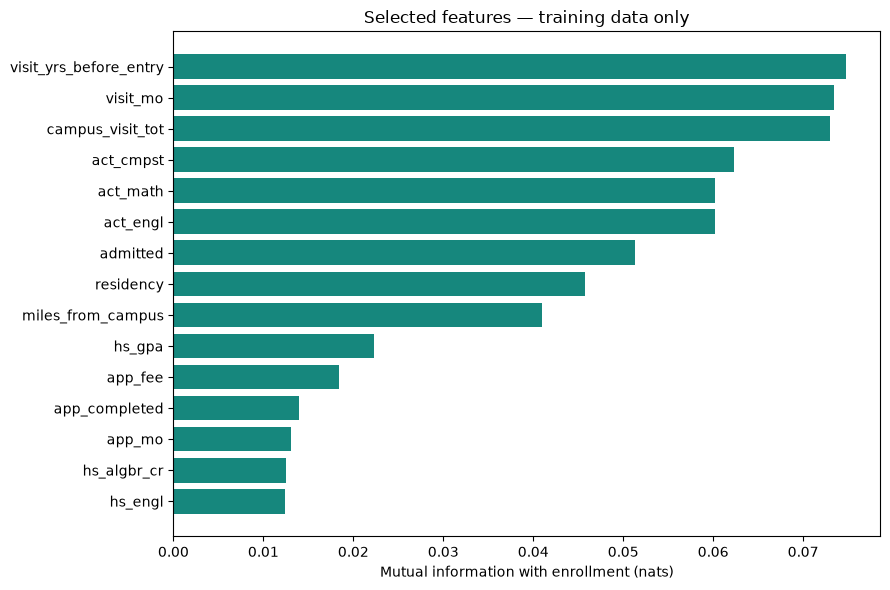

,visit_yrs_before_entry,visit_mo,campus_visit_tot,act_cmpst,act_math,act_engl,admitted,residency,miles_from_campus,hs_gpa,app_fee,app_completed,app_mo,hs_algbr_cr,hs_engl,enrolled
0,NaN,NaN,0,11.0,15.0,10.0,0,0,855.0,2.15,0,1,11,4.0,9.0,0
1,NaN,NaN,0,11.0,14.0,7.0,0,1,307.0,2.14,0,1,12,4.0,8.0,0
2,NaN,NaN,0,11.0,16.0,10.0,0,0,534.0,2.67,0,1,11,4.0,NaN,0
3,NaN,NaN,0,11.0,13.0,NaN,0,2,29.0,2.84,0,1,10,4.0,10.0,0
4,NaN,NaN,0,12.0,15.0,9.0,0,1,226.0,2.22,1,1,8,4.0,NaN,0


In [6]:
selected_ranking = ranking.loc[ranking["selected"], ["feature", "mi_nats"]]
figure, axis = plt.subplots(figsize=(9, 6))
axis.barh(selected_ranking["feature"], selected_ranking["mi_nats"], color="#16877d")
axis.invert_yaxis()
axis.set(xlabel="Mutual information with enrollment (nats)", title="Selected features — training data only")
figure.tight_layout()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
figure.savefig(OUTPUT_DIR / "selected_feature_information.png", dpi=180)
display(figure)
plt.close(figure)
display(training[selected + [TARGET]].head())


## 6. Save the data, ranking, and selection summary
Export original numeric values, not scoring bins, so the model can apply its own preprocessing. The saved split is checked again in notebook 04.


In [7]:
output_dir = OUTPUT_DIR
output_dir.mkdir(parents=True, exist_ok=True)
# Export raw values, not bins: later models can choose their own preprocessing.
columns = selected + [TARGET]
dataset[columns].to_csv(output_dir / "reduced_dataset.csv", index=False)
training[columns].to_csv(output_dir / "reduced_train.csv", index=False)
validation[columns].to_csv(output_dir / "reduced_validation.csv", index=False)
testing[columns].to_csv(output_dir / "reduced_test.csv", index=False)
ranking.to_csv(output_dir / "feature_rankings.csv", index=False)
summary = {
    "method": "Quantile-binned mutual information + symmetric-uncertainty redundancy filter",
    "input": str(input_file.resolve()),
    "target": TARGET,
    "rows": len(dataset),
    "unlabeled_rows_excluded_from_split": int(dataset[TARGET].isna().sum()),
    "train_rows": len(training),
    "validation_rows": len(validation),
    "test_rows": len(testing),
    "split": "Training 2022 - 2024, Validation 2025, Testing 2026",
    "training_entry_years": [2022, 2023, 2024],
    "validation_entry_year": 2025,
    "reserved_test_entry_year": 2026,
    "original_predictors": len(dataset.columns) - 1,
    "derived_features": ["visit_yrs_before_entry"],
    "requested_top_k": TOP_K,
    "selected_features": selected,
    "excluded_columns": {key: value for key, value in EXCLUDED.items() if key in dataset},
    "prediction_time_assumption": "Before deposit; verify availability of all other fields.",
    "scoring": "Training data only; 10 quantile bins for dense numeric measurements; missingness is a group.",
    "redundancy_threshold": 0.9,
    "evaluation": "No predictive accuracy estimated here. Notebook 04 fits on training rows and evaluates on 2025 validation. 2026 was first scored before this calendar-field revision, so revised 2026 results are not an untouched test.",
}
(output_dir / "selection_summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")

display(pd.Series(summary, dtype=object).to_frame("selection_summary"))
display(pd.DataFrame({"saved_file": ["reduced_dataset.csv", "reduced_train.csv", "reduced_validation.csv", "reduced_test.csv", "feature_rankings.csv", "selection_summary.json", "selected_feature_information.png"]}))
print(f"Saved to {OUTPUT_DIR}")


,selection_summary
method,Quantile-binned mutual information + symmetric...
input,C:\Users\marks\.workspace\school\.DATA4890\dat...
target,enrolled
rows,69541
unlabeled_rows_excluded_from_split,0
train_rows,40745
validation_rows,14829
test_rows,13967
split,"Training 2022 - 2024, Validation 2025, Testing..."
training_entry_years,"[2022, 2023, 2024]"


,saved_file
0,reduced_dataset.csv
1,reduced_train.csv
2,reduced_validation.csv
3,reduced_test.csv
4,feature_rankings.csv
5,selection_summary.json
6,selected_feature_information.png


Saved to C:\Users\marks\.workspace\school\.DATA4890\datathon\datathon\feature_reduction_output
